<a href="https://colab.research.google.com/github/NoDanCoder/AirBnB_clone/blob/master/Semana10/NewtonRaphson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Definamos el sistema usando una lista
Gfea = (lambda x,y,z: 3*x - np.cos(y*z) - 1.5, \
     lambda x,y,z: 4*x**2 - 625*y**2 + 2*y -1, \
     lambda x,y,z: np.exp(-x*y) + 20*z + 9.471975)

In [3]:
Gbonita = (lambda x,y,z: 3*x - y - z - 1, \
     lambda x,y,z: -x + 3*y + z - 3, \
     lambda x,y,z: 2*x + y + 4*z - 7 )


In [4]:
Gbonita[2](1,1,1)

0

In [5]:
#Definamos el vector de funciones
def GetVector(G,r):

  v = np.zeros(len(G))

  for i in range(v.shape[0]):
    v[i] = G[i](r[0],r[1],r[2])

  return v

In [6]:
GetVector(Gbonita,[2,1,2])

array([2., 0., 6.])

In [7]:
# Calculamos la matriz jacobiana
def GetJacobian(G,r,h=1e-4):

  J = np.zeros((r.shape[0],r.shape[0]))

  for i in range(r.shape[0]):

    J[i,0] = (G[i](r[0]+h,r[1],r[2]) - G[i](r[0]-h,r[1],r[2]))/(2*h)
    J[i,1] = (G[i](r[0],r[1]+h,r[2]) - G[i](r[0],r[1]-h,r[2]))/(2*h)
    J[i,2] = (G[i](r[0],r[1],r[2]+h) - G[i](r[0],r[1],r[2]-h))/(2*h)

  return J.T

In [8]:
GetJacobian(Gfea,np.array([1,2,4]))

array([[ 3.00000000e+00,  8.00000000e+00, -2.70670568e-01],
       [ 3.95743288e+00, -2.49800000e+03, -1.35335283e-01],
       [ 1.97871648e+00,  0.00000000e+00,  2.00000000e+01]])

In [9]:
def NewthonRaphson(G,r,tol=1e-10,maxiter=100):

  it = 0
  d = 10

  Distancias = np.array([])

  while d > tol:

    F = GetVector(G,r)
    J = GetJacobian(G,r)

    InvJ = np.linalg.inv(J)

    r_new = r - np.dot(InvJ,F)

    d = np.linalg.norm(r_new - r)

    Distancias = np.append(Distancias,d)

    r = r_new
    it += 1

    if it > maxiter:
      break

  return r,Distancias

In [10]:
r0 = np.array([0.,0.5,0.6])
r,Distancias = NewthonRaphson(Gbonita,r0)

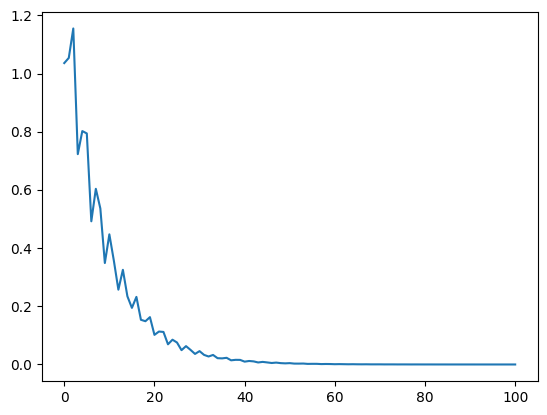

In [11]:
plt.plot(Distancias)

In [12]:
r

array([1.00000188, 1.00000375, 0.99999061])

In [62]:
import sympy as sym

In [63]:
x, y = sym.symbols('x y', real=True)

In [64]:
z = x + sym.I*y

In [65]:
def f(z):
  return z**3 - 1

In [66]:
F = [sym.re(f(z)), sym.im(f(z))]

In [68]:
J = sym.Matrix(F).jacobian([x, y])

In [69]:
J

Matrix([
[3*x**2 - 3*y**2,          -6*x*y],
[          6*x*y, 3*x**2 - 3*y**2]])

In [70]:
Fn = sym.lambdify([x, y], F, "numpy")
Jn = sym.lambdify([x, y], J, "numpy")

In [71]:
def NewtonRaphson(z0, Fn, Jn, tol=1e-7, maxiter=100):
    r = np.array(z0, dtype=float)
    it = 0
    d = 10
    Distancias = np.array([])

    while d > tol and it < maxiter:
        F = np.array(Fn(*r), dtype=float)
        J = np.array(Jn(*r), dtype=float)
        InvJ = np.linalg.inv(J)
        r_new = r - np.dot(InvJ, F)
        d = np.linalg.norm(r_new - r)
        Distancias = np.append(Distancias, d)
        r = r_new
        it += 1

    return r, Distancias


print(newton_raphson([0.5, 0.5], Fn, Jn))

[-0.5        0.8660254]


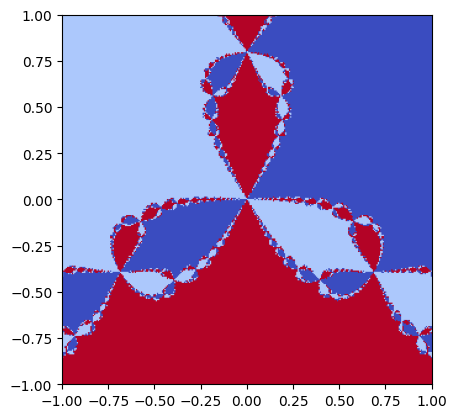

In [74]:
roots = np.array([
    [-0.5, np.sqrt(3) / 2],
    [-0.5, -np.sqrt(3) / 2],
    [1.0, 0.0],
])
colors = [20, 100, 255]

N = 300
x_grid = np.linspace(-1, 1, N)
y_grid = np.linspace(-1, 1, N)
Fractal = np.zeros((N, N), np.int64)

for i, yi in enumerate(y_grid):
    for j, xj in enumerate(x_grid):
        try:
            root = newton_raphson([xj, yi], Fn, Jn)
        except np.linalg.LinAlgError:
            continue
        nearest = np.argmin(np.linalg.norm(roots - root, axis=1))
        Fractal[i, j] = colors[nearest]

plt.imshow(Fractal.T, cmap="coolwarm", extent=[-1, 1, -1, 1])
plt.show()